In [1]:
from tqdm import tqdm
from astropy.table import Table
import numpy as np
import h5py
import pandas as pd
import data
import matplotlib.pyplot as plt
import sample
import halotools
from scipy import stats
from multicam.multicam import MultiCAM
from multicam.multicam import MultiCamSampling
import pickle
from constants import TNG_H, HYDRO_STELLAR_MASS_MIN

COLOR_CUT = 0.85

In [ ]:
print('wefwe')

In [ ]:
## Load data ###
hydro_full = pd.read_csv(
    'data/cache_files/hydro_color_tree_subhaloflag_check_data.csv',
    usecols=[
        'SubhaloMass', 'StellarMass', 'x', 'y', 'z',
        'logStellarMass', 'logSubhaloMass', 'g-i',
        'vpeak', 'a12', 'mpeak',
        *[f'mpeak_mah{ii}' for ii in range(100)]
    ]
)

print("\nHydro Table")
print(len(hydro_full))

print("\nCache files read in!")

# 1.4 * 10^8 minimum on Stellar Mass for hydro catalog
hydro_full = hydro_full[hydro_full['StellarMass'] >= HYDRO_STELLAR_MASS_MIN] # divide by h to get Msun
print("\nNew Hydro Table Length:")
print(len(hydro_full))

# Add z12 column to dmo_full
hydro_full['z12'] = (1 / hydro_full['a12']) - 1
print(hydro_full)


Hydro Table
101364

Cache files read in!

New Hydro Table Length:
21771
         SubhaloMass   StellarMass          x          y          z  \
0       2.747794e+14  1.638342e+12   0.849091  26.326996  18.306934   
1       3.666623e+13  2.573102e+11   0.106473  24.633322  16.900553   
2       7.734555e+12  2.885268e+11   0.853112  26.725748  17.510680   
3       3.253667e+12  6.276475e+10   0.768784  26.518290  15.530523   
4       2.980181e+12  8.770330e+10   1.426592  26.341442  19.041204   
...              ...           ...        ...        ...        ...   
100110  5.506356e+09  2.442531e+08  65.244316  14.453114  32.561405   
100239  4.163340e+09  3.376348e+08  21.512703  73.824860  19.064798   
100245  5.602026e+09  2.337010e+08  23.715452  36.721306  42.095657   
100354  3.967491e+09  3.418285e+08  40.340150  37.721676  57.260925   
100384  4.172430e+09  3.815481e+08  66.217720  60.654682  54.770990   

        logSubhaloMass  logStellarMass       vpeak       a12         mpeak

In [3]:
hydro_data_mpeak_cut = hydro_full[(hydro_full['mpeak'] >= (10**11))&(hydro_full['mpeak'] <= (10**12))]
print(hydro_data_mpeak_cut)

        SubhaloMass   StellarMass          x          y          z  \
15     6.426670e+11  1.959215e+10   0.379645  25.079288  16.587719   
20     3.942948e+11  2.328852e+10   0.303943  27.653301  17.940432   
21     3.774756e+11  1.898052e+10  74.735700  24.650198  16.704525   
22     4.092979e+11  1.634936e+10   1.857714  25.990385  19.931873   
23     2.735071e+11  2.056505e+10   0.719776  26.065008  17.520130   
...             ...           ...        ...        ...        ...   
58329  2.355737e+10  2.111694e+09  51.652386  10.073790  12.564201   
60587  2.968423e+10  7.676879e+08   1.785950  52.558304  54.282352   
61542  2.030373e+10  1.947287e+09  43.591217  66.893105  46.197330   
62363  2.186401e+10  1.521510e+09   2.042494  25.050950  18.758776   
65827  2.293682e+10  7.631336e+08  12.822639  50.124954  46.916100   

       logSubhaloMass  logStellarMass      vpeak       a12         mpeak  ...  \
15          11.807986       10.292082  223.23720  0.500000  8.567395e+11  ... 

In [4]:
from multicam_tng_utils import get_msmhmr

In [5]:
log10_stellar_mass = np.array(np.log10(hydro_data_mpeak_cut['StellarMass']))
log10_mpeak = np.array(np.log10(hydro_data_mpeak_cut['mpeak']))

m_star_dev, (m, b) = get_msmhmr(log10_stellar_mass, 
                                log10_mpeak,
                                mass_bin = (11, 12), n_bins = 11)
print(m_star_dev, (m, b))

[-0.03634345  0.10160283 -0.08735532 ...  0.21438808  0.12138877
 -0.08627693] (np.float64(0.518519435033275), np.float64(-7.791837259377634))


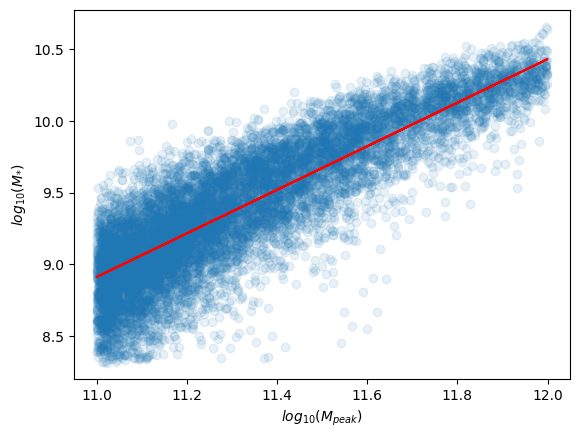

In [6]:
plt.scatter(log10_mpeak, log10_stellar_mass, alpha = .1);
plt.xlabel(r"$log_{10}(M_{peak})$");
plt.ylabel(r"$log_{10}(M_{*})$");

ypred = np.log10(10 ** (m * log10_mpeak + b) * 10**log10_mpeak)
plt.plot(log10_mpeak, ypred, color = "red");

In [7]:
# Define Targets & features
color = hydro_data_mpeak_cut['g-i']
targets = np.array([color, m_star_dev]).T
mah = np.array([hydro_data_mpeak_cut[f'mpeak_mah{ii}'] for ii in range(100)]).T
features = mah
print(targets.shape, features.shape)

(11161, 2) (11161, 100)


In [8]:
n_features = 100
n_targets = 2
model = MultiCAM(n_features, n_targets)

In [9]:
model.fit(features, targets)

In [10]:
pred = model.predict(features)

In [11]:
pred.shape

(11161, 2)

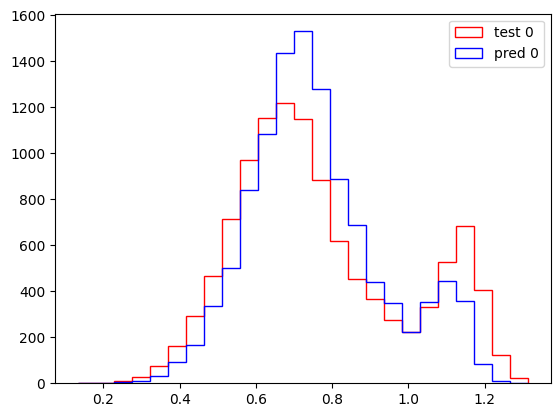

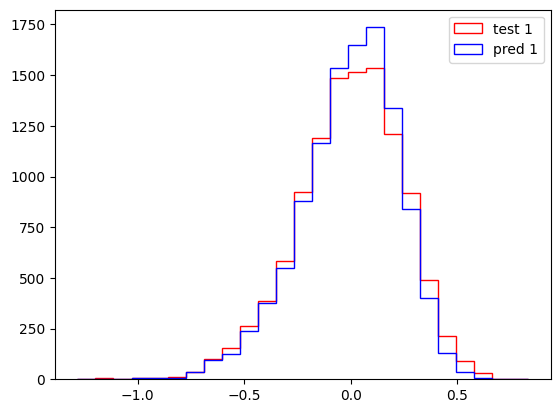

In [12]:
for i in range(targets.shape[1]):
    plt.figure()
    _, bins, _ = plt.hist(targets[:, i], histtype='step', bins=25, label=f'test {i}', color='r')
    plt.hist(pred[:, i],    histtype='step', bins= bins, label=f'pred {i}', color='b')
    plt.legend()
    plt.show()

In [13]:
# Compute Spearman
from scipy import stats
res = stats.spearmanr(targets[:,0], pred[:,0])
print('Spearman coefficent color = ', res)

res = stats.spearmanr(targets[:,1], pred[:,1])
print('Spearman coefficent dev = ', res)

Spearman coefficent color =  SignificanceResult(statistic=np.float64(0.7191707507629709), pvalue=np.float64(0.0))
Spearman coefficent dev =  SignificanceResult(statistic=np.float64(0.6990004953649244), pvalue=np.float64(0.0))


In [14]:
n_features = 100
n_targets = 2
model_samp = MultiCamSampling(n_features, n_targets)

In [15]:
model_samp.fit(features, targets)

In [16]:
pred_sampling = model_samp.sample(features)

In [17]:
pred_sampling.shape

(11161, 2)

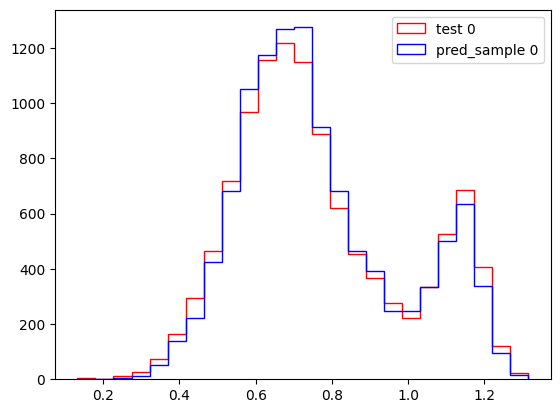

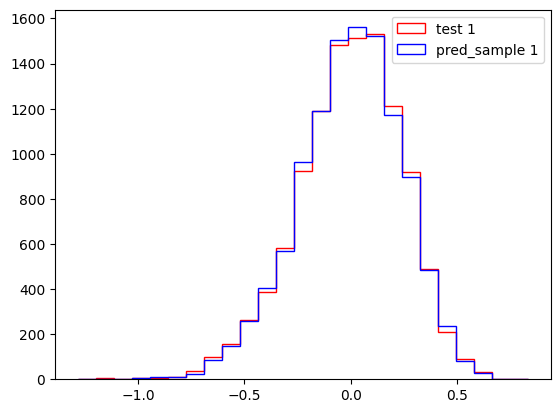

In [18]:
for i in range(targets.shape[1]):
    plt.figure()
    _, bins, _  = plt.hist(targets[:, i], histtype='step', bins=25, label=f'test {i}', color='r')
    plt.hist(pred_sampling[:, i],    histtype='step', bins= bins, label=f'pred_sample {i}', color='b')
    plt.legend()
    plt.show()

In [19]:
# Truth
mpeak = np.array(np.log10(hydro_data_mpeak_cut['mpeak']))
mstar_truth = m_star_dev + np.log10(10 ** (m * mpeak + b) * 10**mpeak)

# MultiCAM
m_star_dev_pred = pred[:, 1]
mstar_pred = m_star_dev_pred + np.log10(10 ** (m * mpeak + b) * 10**mpeak)

# MultiCAM Sampling
m_star_dev_sample = pred_sampling[:, 1]
mstar_pred_sample = m_star_dev_sample + np.log10(10 ** (m * mpeak + b) * 10**mpeak)

mstar_truth, mstar_pred

(array([10.2920821 , 10.3671418 , 10.27830811, ...,  9.28943001,
         9.1822747 ,  8.88260058], shape=(11161,)),
 array([10.38156003, 10.14145208, 10.42010919, ...,  9.4178027 ,
         9.4794632 ,  9.23746214], shape=(11161,)))

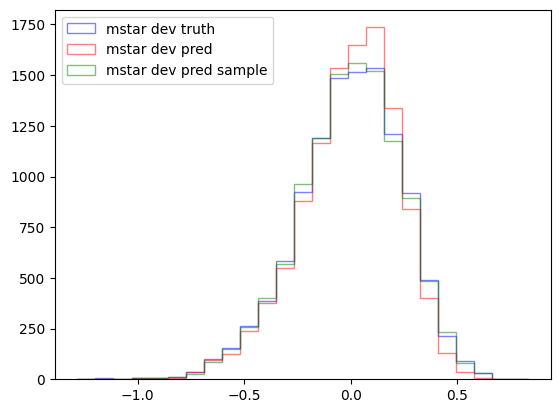

In [20]:
_, bins, _  = plt.hist(m_star_dev, bins=25,  histtype='step', alpha=0.5, label='mstar dev truth', color='blue');
plt.hist(m_star_dev_pred, bins= bins,  histtype='step', alpha=0.5, label='mstar dev pred', color='red');
plt.hist(m_star_dev_sample, bins=bins,  histtype='step', alpha=0.5, label='mstar dev pred sample', color='green');
plt.legend();

11161 11161 11161 11161


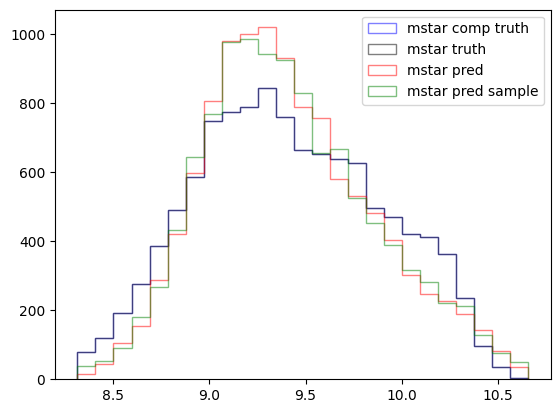

In [21]:
_, bins, _  = plt.hist(mstar_truth, bins=25,  histtype='step', alpha=0.5, label='mstar comp truth', color='blue');
plt.hist(np.array(np.log10(hydro_data_mpeak_cut['StellarMass'])), bins=bins,  histtype='step', alpha=0.5, label='mstar truth', color='black');
plt.hist(mstar_pred, bins=bins,  histtype='step', alpha=0.5, label='mstar pred', color='red');
plt.hist(mstar_pred_sample, bins=bins,  histtype='step', alpha=0.5, label='mstar pred sample', color='green');
plt.legend();
print(len(mstar_truth), len(mstar_pred), len(mstar_pred_sample), len(np.array(np.log10(hydro_data_mpeak_cut['StellarMass']))))

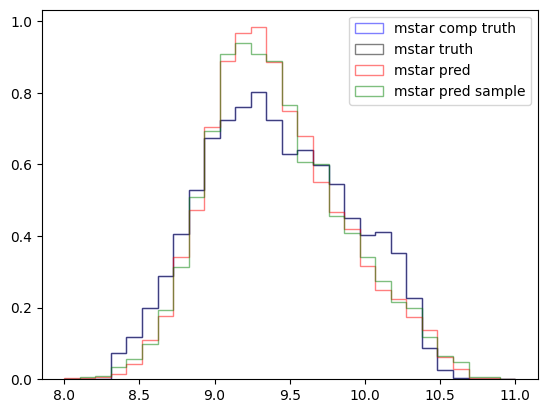

In [22]:
bins = np.linspace(8, 11, 30)
plt.hist(mstar_truth, bins=bins,  histtype='step', alpha=0.5, label='mstar comp truth', density = True, color='blue');
plt.hist(np.array(np.log10(hydro_data_mpeak_cut['StellarMass'])), bins=bins,  histtype='step', alpha=0.5, label='mstar truth', density = True, color='black');
plt.hist(mstar_pred, bins=bins,  histtype='step', alpha=0.5, label='mstar pred', density = True, color='red');
plt.hist(mstar_pred_sample, bins=bins,  histtype='step', alpha=0.5, label='mstar pred sample', density = True, color='green');
plt.legend();

In [24]:
## Compute TPCF ###
from halotools.mock_observables import return_xyz_formatted_array, tpcf_jackknife

def generate_randoms(Lbox, number):
    """Generate randoms to be used for tpcf_jackknife
    Args:
        Lbox: size of TNG simulation box
        number: desired number of randoms, i.e. 10,000
    Return:
        Nran: xyz formatted array of uniform random variables
    """
    Xran = np.random.uniform(0, Lbox, number)
    Yran = np.random.uniform(0, Lbox, number)
    Zran = np.random.uniform(0, Lbox, number)
    Nran = return_xyz_formatted_array(Xran, Yran, Zran)
    return Nran

## Look at mstar between 9.3 and 10
## Kuan suggests use: 9.5 to 10.2
# Note hydro_full for truth (no unness cuts)
hydro_mstar_cut = hydro_full[(np.log10(hydro_full['StellarMass']) > 9.5) & (np.log10(hydro_full['StellarMass']) < 10.2)]

# Note use mpeak_cut cause that's what we apply mcam to
hydro_data_mpeak_cut['pred_color'] = pred[:, 0]
hydro_mstar_pred = hydro_data_mpeak_cut[(mstar_pred > 9.5) & (mstar_pred < 10.2)]

hydro_mstar_pred_sample = hydro_data_mpeak_cut[(mstar_pred_sample > 9.5) & (mstar_pred_sample < 10.2)]

Lbox = 110.7 * TNG_H
rbins = np.logspace(np.log10(0.1), np.log10(24.9), 16)
rbin_centers = 0.5 * (rbins[1:] + rbins[:-1])
randoms = generate_randoms(Lbox, 50000)
# Kuan: use more randoms...

/tmp/ipykernel_18282/1056298229.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  hydro_data_mpeak_cut['pred_color'] = pred[:, 0]


In [25]:
print(len(hydro_mstar_cut), len(hydro_mstar_pred))

4054 3601


In [26]:
xi_truth, cov_truth = tpcf_jackknife(
        return_xyz_formatted_array(hydro_mstar_cut['x'] * TNG_H, hydro_mstar_cut['y'] * TNG_H, hydro_mstar_cut['z'] * TNG_H),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_pred, cov_pred = tpcf_jackknife(
        return_xyz_formatted_array(hydro_mstar_pred['x'] * TNG_H, hydro_mstar_pred['y'] * TNG_H, hydro_mstar_pred['z'] * TNG_H),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

In [27]:
xi_pred_samp, cov_pred_samp = tpcf_jackknife(
        return_xyz_formatted_array(hydro_mstar_pred_sample['x']* TNG_H, hydro_mstar_pred_sample['y']* TNG_H, hydro_mstar_pred_sample['z'])* TNG_H,
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

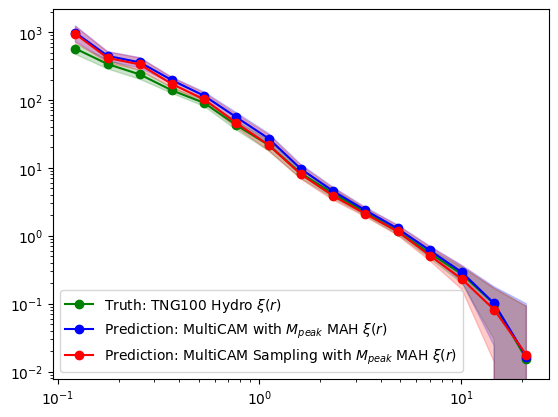

In [ ]:
plt.plot(rbin_centers, xi_truth, marker='o', color= 'green', label=r'Truth: TNG100 Hydro $\xi(r)$');
plt.fill_between(rbin_centers, xi_truth - np.sqrt(np.diag(cov_truth)), xi_truth + np.sqrt(np.diag(cov_truth)), color = 'green', alpha = 0.2)
plt.plot(rbin_centers, xi_pred, marker='o', color= 'blue', label=r'Prediction: MultiCAM with $M_{peak}$ MAH $\xi(r)$');
plt.fill_between(rbin_centers, xi_pred - np.sqrt(np.diag(cov_pred)), xi_pred + np.sqrt(np.diag(cov_pred)), color = 'blue', alpha = 0.2)

plt.plot(rbin_centers, xi_pred_samp, marker='o', color= 'red', label=r'Prediction: MultiCAM Sampling with $M_{peak}$ MAH $\xi(r)$');
plt.fill_between(rbin_centers, xi_pred_samp - np.sqrt(np.diag(cov_pred_samp)), xi_pred + np.sqrt(np.diag(cov_pred_samp)), color = 'red', alpha = 0.2)

plt.yscale('log')
plt.xscale('log')
plt.xlabel(r'$r \, \rm{[Mpc/h]}$')
plt.legend()
plt.show()

In [33]:
red_pred = hydro_mstar_pred[hydro_mstar_pred['pred_color'] > COLOR_CUT]
blue_pred = hydro_mstar_pred[hydro_mstar_pred['pred_color'] <= COLOR_CUT]

red_table = hydro_mstar_cut[hydro_mstar_cut['g-i'] > COLOR_CUT]
blue_table = hydro_mstar_cut[hydro_mstar_cut['g-i'] <= COLOR_CUT]

print(len(red_pred), len(blue_pred), len(red_table), len(blue_table))

1347 2254 1586 2468


In [34]:
hydro_mstar_pred_sample

,SubhaloMass,StellarMass,x,y,z,logSubhaloMass,logStellarMass,vpeak,a12,mpeak,...,mpeak_mah93,mpeak_mah94,mpeak_mah95,mpeak_mah96,mpeak_mah97,mpeak_mah98,mpeak_mah99,g-i,z12,pred_color
21,3.774756e+11,1.898052e+10,74.735700,24.650198,16.704525,11.576889,10.278308,254.800310,0.483092,9.065073e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.159027,1.07,0.839877
22,4.092979e+11,1.634936e+10,1.857714,25.990385,19.931873,11.612040,10.213501,219.668560,0.344828,5.439045e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.041630,1.90,0.798425
26,3.041727e+11,1.426524e+10,0.822764,26.144829,19.978884,11.483120,10.154279,198.722000,0.290698,3.719824e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.093975,2.44,0.932592
27,2.883535e+11,8.203994e+09,1.252321,26.284533,19.722652,11.459926,9.914025,155.845320,0.354610,2.919132e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.535936,1.82,0.728791
28,3.212165e+11,1.061568e+10,0.617334,26.386446,19.905940,11.506798,10.025948,161.096850,0.444444,4.735706e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.061354,1.25,0.709083
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43808,9.839331e+10,1.367333e+09,51.865930,70.908910,40.928940,10.992966,9.135874,112.168816,0.301205,1.169157e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.800770,2.32,0.841461
44016,9.462367e+10,1.877300e+09,74.356280,27.821562,15.193963,10.976000,9.273534,120.516426,0.473934,1.738507e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,0.884567,1.11,0.815999
44167,7.891032e+10,3.664914e+09,23.131289,41.120567,52.390144,10.897134,9.564064,132.559080,0.333333,1.876783e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.070267,2.00,0.915956
44322,5.453946e+10,2.281331e+09,16.062790,49.695970,48.841070,10.736711,9.358189,125.499280,0.311526,1.314737e+11,...,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.066578,2.21,0.954187


In [35]:
red_pred_samp = hydro_mstar_pred_sample[hydro_mstar_pred_sample['pred_color'] > COLOR_CUT]
blue_pred_samp = hydro_mstar_pred_sample[hydro_mstar_pred_sample['pred_color'] <= COLOR_CUT]

In [36]:
## Compute TPCF ###
from halotools.mock_observables import return_xyz_formatted_array, tpcf_jackknife

Lbox = 110.7 * TNG_H
rbins = np.logspace(np.log10(0.1), np.log10(24.9), 16)
rbin_centers = 0.5 * (rbins[1:] + rbins[:-1])
randoms = generate_randoms(Lbox, 50000)


xi_red_truth, cov_red_truth = tpcf_jackknife(
        return_xyz_formatted_array(red_table['x'], red_table['y'], red_table['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_blue_truth, cov_blue_truth = tpcf_jackknife(
        return_xyz_formatted_array(blue_table['x'], blue_table['y'], blue_table['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_red_pred, cov_red_pred = tpcf_jackknife(
        return_xyz_formatted_array(red_pred['x'], red_pred['y'], red_pred['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_blue_pred, cov_blue_pred = tpcf_jackknife(
        return_xyz_formatted_array(blue_pred['x'], blue_pred['y'], blue_pred['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_red_pred_samp, cov_red_pred_samp = tpcf_jackknife(
        return_xyz_formatted_array(red_pred_samp['x'], red_pred_samp['y'], red_pred_samp['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

xi_blue_pred_samp, cov_blue_pred_samp = tpcf_jackknife(
        return_xyz_formatted_array(blue_pred_samp['x'], blue_pred_samp['y'], blue_pred_samp['z']),
        randoms, rbins, Nsub=3, period=Lbox, num_threads='max')

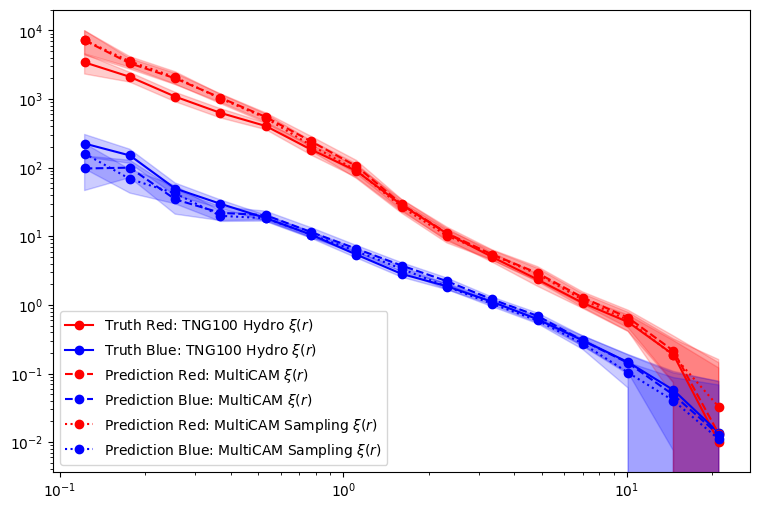

In [45]:
plt.figure(figsize=(9, 6))

plt.plot(rbin_centers, xi_red_truth, marker = 'o', color = 'red', label=r'Truth Red: TNG100 Hydro $\xi(r)$');
plt.fill_between(rbin_centers, xi_red_truth - np.sqrt(np.diag(cov_red_truth)), xi_red_truth + np.sqrt(np.diag(cov_red_truth)), 
                 color = 'red', alpha = 0.2)
plt.plot(rbin_centers, xi_blue_truth, marker = 'o', color = 'blue', label=r'Truth Blue: TNG100 Hydro $\xi(r)$');
plt.fill_between(rbin_centers, xi_blue_truth - np.sqrt(np.diag(cov_blue_truth)), xi_blue_truth + np.sqrt(np.diag(cov_blue_truth)), 
                 color = 'blue', alpha = 0.2)


plt.plot(rbin_centers, xi_red_pred, marker = 'o', color = 'red', linestyle = "--", label=r'Prediction Red: MultiCAM $\xi(r)$');
plt.fill_between(rbin_centers, xi_red_pred - np.sqrt(np.diag(cov_red_pred)), xi_red_pred + np.sqrt(np.diag(cov_red_pred)), 
                 color = 'red', alpha = 0.2)

plt.plot(rbin_centers, xi_blue_pred, marker = 'o', color = 'blue', linestyle = "--", label=r'Prediction Blue: MultiCAM $\xi(r)$');
plt.fill_between(rbin_centers, xi_blue_pred - np.sqrt(np.diag(cov_blue_pred)), xi_blue_pred + np.sqrt(np.diag(cov_blue_pred)), 
                 color = 'blue', alpha = 0.2)

plt.plot(rbin_centers, xi_red_pred_samp, marker = 'o', color = 'red', linestyle = "dotted", label=r'Prediction Red: MultiCAM Sampling $\xi(r)$');
plt.fill_between(rbin_centers, xi_red_pred_samp - np.sqrt(np.diag(cov_red_pred_samp)), xi_red_pred_samp + np.sqrt(np.diag(cov_red_pred_samp)), 
                 color = 'red', alpha = 0.2)

plt.plot(rbin_centers, xi_blue_pred_samp, marker = 'o', color = 'blue', linestyle = "dotted", label=r'Prediction Blue: MultiCAM Sampling $\xi(r)$');
plt.fill_between(rbin_centers, xi_blue_pred_samp - np.sqrt(np.diag(cov_blue_pred_samp)), xi_blue_pred_samp + np.sqrt(np.diag(cov_blue_pred_samp)), 
                 color = 'blue', alpha = 0.2)

plt.yscale('log')
plt.xscale('log')
plt.legend(loc='lower left')
plt.show()

In [44]:
# Next Steps:
# Add the multicam sampling pred to the above plots + errors
# Make this a script


# Note: Cov with halotools (need to check if multiply by 26 or not)

# Will look exactly the same for dmo_hydro implementation, but... (mpeak throughout)
# Might have to do sham to compute the deviations
# Also, you train multicam with matches (in same mpeak bin)

In [ ]:
df = pd.read_csv()